# 03 Feature engineering (Part B2)

All features live in `src/features.py` so that CV, the final model and the scoring service (Part E) compute them identically. This notebook builds them, audits each family against the decision point, and saves the feature table for Sections 4 to 12.

**Timing rules (from Section 1):**
1. History uses only loans disbursed on an **earlier date**. Same-day loans are excluded because their order is unknown (21,425 loans share a day with another loan from the same customer).
2. A past outcome counts only once it was **observable**: `due_date + LABEL_LAG_DAYS < current disbursement_date`, and the loan has a label. The lag is 0 days by default; raise it if NkwaPay declares defaults after a grace period.
3. Macro indicators for year *Y* are joined to loans disbursed in *Y + 1*.

Test loans are included as *history* (NkwaPay knows a customer's past loans) but never contribute outcomes.

In [1]:
import sys; sys.path.append("..")
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from sklearn.metrics import roc_auc_score
from src.config import set_seed, FIGURES, DATA_PROCESSED
from src.data import load_loans
from src import features as F
set_seed()
loans = pd.concat([load_loans("train").assign(split="train"), load_loans("test").assign(split="test")], ignore_index=True)
X = F.build_features(loans)
tr = loans.split.eq("train").to_numpy()
y = loans.loc[tr, "target"].astype(int)
print(X.shape, "| families:", {k: len(v) for k, v in
      {"loan": F.LOAN, "history": F.HISTORY, "calendar": F.CALENDAR, "macro": F.MACRO, "categorical": F.CATEGORICAL}.items()})

(83587, 30) | families: {'loan': 6, 'history': 14, 'calendar': 4, 'macro': 4, 'categorical': 2}


## 3.1 Feature dictionary

In [2]:
desc = {
    "log_amount": "log1p(Total_Amount)", "duration": "Term in days", "amount_per_day_log": "log1p(amount / duration)",
    "Lender_portion_Funded": "Summed lender share of the loan", "n_lenders": "Co-funding lenders (1 or 2)", "is_new": "New_versus_Repeat == New",
    "n_prev_loans": "Loans disbursed on earlier dates", "n_prev_resolved": "Earlier loans with an observable outcome",
    "n_prev_defaults": "Observable earlier defaults", "prev_default_rate": "Smoothed past default rate (prior = portfolio rate known at the time, weight 5)",
    "has_resolved_history": "Any observable past outcome", "n_active_loans": "Earlier loans not yet due", "active_amount_log": "log1p(amount still outstanding)",
    "days_since_last_loan": "Days since previous disbursement", "days_since_last_default": "Days since last observable default",
    "prev_amount_mean_log": "log1p(mean past amount)", "prev_amount_max_log": "log1p(max past amount)",
    "amount_vs_prev_mean": "Current amount / mean past amount", "prev_duration_mean": "Mean past term", "n_prev_lenders": "Distinct past lenders",
    "disb_month": "Month", "disb_weekday": "Weekday (0 = Monday)", "disb_day": "Day of month", "disb_month_end": "Last 3 days of month",
    "macro_inflation": "CPI inflation, previous year", "macro_fx_change": "Currency depreciation vs USD, previous year (%)",
    "macro_deposit_rate": "Deposit rate, previous year", "macro_unemployment": "Unemployment, previous year",
    "loan_type": "Product (rare -> Other, unseen -> Unknown, fitted per fold)", "lender_id": "Primary lender (same grouping)",
}
fam = {c: k for k, cols in {"loan": F.LOAN, "history": F.HISTORY, "calendar": F.CALENDAR, "macro": F.MACRO, "categorical": F.CATEGORICAL}.items() for c in cols}
Xtr = X[tr]
dic = pd.DataFrame({"family": pd.Series(fam), "definition": pd.Series(desc),
                    "missing_share": Xtr.isna().mean().round(3),
                    "AUC (train, univariate)": pd.Series({c: roc_auc_score(y, Xtr[c].fillna(Xtr[c].median())) for c in F.NUMERIC}).round(3)})
dic.to_csv(FIGURES.parent / "03_feature_dictionary.csv")
dic

,family,definition,missing_share,"AUC (train, univariate)"
Lender_portion_Funded,loan,Summed lender share of the loan,0.000,0.567
active_amount_log,history,log1p(amount still outstanding),0.000,0.300
amount_per_day_log,loan,log1p(amount / duration),0.000,0.511
amount_vs_prev_mean,history,Current amount / mean past amount,0.090,0.582
days_since_last_default,history,Days since last observable default,0.999,0.499
days_since_last_loan,history,Days since previous disbursement,0.090,0.695
disb_day,calendar,Day of month,0.000,0.453
disb_month,calendar,Month,0.000,0.432
disb_month_end,calendar,Last 3 days of month,0.000,0.490
disb_weekday,calendar,Weekday (0 = Monday),0.000,0.483


Univariate AUC above 0.5 means higher values go with default; below 0.5 means the reverse. These are rough signals only (they ignore grouping by customer and the time drift); Section 4 measures performance properly. Missing values arise only where there is no earlier loan; the model pipeline imputes them and keeps an indicator.

## 3.2 Borrower history

Only **89 training loans** have an observable previous default. Customers who default rarely borrow again, so "past defaults" is almost always zero and cannot carry much signal. The useful history is *how much and how often* someone borrows.

Loans with an observable past default: 89 of 66,520


Customers who ever defaulted: 1,016; for 95% of them the default is their last loan in the data


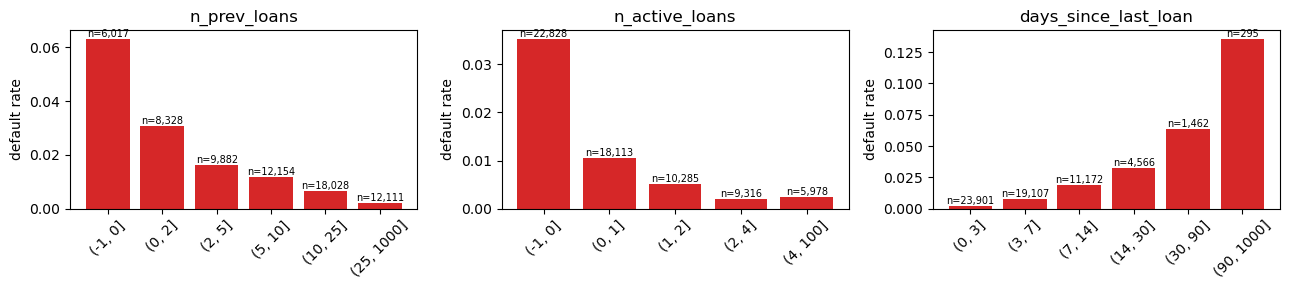

In [3]:
print(f"Loans with an observable past default: {(Xtr.n_prev_defaults > 0).sum()} of {tr.sum():,}")
cust = loans[tr].groupby("customer_id")
last_is_default = cust.apply(lambda g: g.sort_values("disbursement_date").target.iloc[-1] == 1, include_groups=False)
ever = cust.target.max() == 1
print(f"Customers who ever defaulted: {ever.sum():,}; for {last_is_default[ever].mean():.0%} of them the default is their last loan in the data")

bins = {"n_prev_loans": [-1, 0, 2, 5, 10, 25, 1000], "n_active_loans": [-1, 0, 1, 2, 4, 100], "days_since_last_loan": [0, 3, 7, 14, 30, 90, 1000]}
fig, axes = plt.subplots(1, 3, figsize=(13, 3))
for ax, (c, b) in zip(axes, bins.items()):
    r = y.groupby(pd.cut(Xtr[c], b), observed=True).agg(["mean", "size"])
    ax.bar(r.index.astype(str), r["mean"], color="tab:red"); ax.set(title=c, ylabel="default rate"); ax.tick_params(axis="x", rotation=45)
    for i, n in enumerate(r["size"]): ax.text(i, r["mean"].iloc[i], f"n={n:,}", ha="center", va="bottom", fontsize=7)
plt.tight_layout(); plt.savefig(FIGURES / "03_history_signal.png", dpi=200); plt.show()

Default risk falls steeply with the number of earlier loans (6.3% with no earlier loan, 0.2% after 25+), and borrowers with no loan currently outstanding default more than those who roll loans continuously. Long gaps since the last loan go with much higher risk (13.5% after 90+ days). The strongest univariate features are days_since_last_loan (AUC 0.70), duration (0.67) and prev_default_rate (0.67). Note that prev_default_rate is mostly the smoothing prior, the portfolio default rate known on that date, so part of its signal is *time* rather than the borrower; Section 4's temporal split will show how much survives. History is therefore informative, but mostly as *experience and engagement*, which also means first-time and returning-after-a-gap borrowers carry most of the risk.

## 3.3 Ratio features and their leakage audit

Each ratio must use only inputs available at the decision point.

In [4]:
pd.DataFrame([
    ("amount_per_day_log", "Total_Amount, duration", "pass", "Both chosen at application"),
    ("amount_vs_prev_mean", "Total_Amount, earlier loans' amounts", "pass", "Earlier loans only (replay-tested)"),
    ("prev_default_rate", "observable past outcomes, time-aware prior", "pass", "Prior uses only outcomes observable before the loan"),
    ("Lender_portion_Funded", "funding split", "pass, confirm", "Assumes split is fixed before approval (Section 1)"),
    ("repay / amount", "Total_Amount_to_Repay", "FAIL, excluded", "Inflated after default (Section 1, AUC 0.98)"),
    ("lender repay / funded", "Lender_portion_to_be_repaid", "FAIL, excluded", "Derived from the same column"),
], columns=["feature", "inputs", "audit", "reason"])

,feature,inputs,audit,reason
0,amount_per_day_log,"Total_Amount, duration",pass,Both chosen at application
1,amount_vs_prev_mean,"Total_Amount, earlier loans' amounts",pass,Earlier loans only (replay-tested)
2,prev_default_rate,"observable past outcomes, time-aware prior",pass,Prior uses only outcomes observable before the...
3,Lender_portion_Funded,funding split,"pass, confirm",Assumes split is fixed before approval (Sectio...
4,repay / amount,Total_Amount_to_Repay,"FAIL, excluded","Inflated after default (Section 1, AUC 0.98)"
5,lender repay / funded,Lender_portion_to_be_repaid,"FAIL, excluded",Derived from the same column


## 3.4 Macro indicators

Only four indicators exist for both Ghana and Kenya (inflation, exchange rate, deposit rate, unemployment); lending rate, real rate and spread are missing for Ghana. The exchange rate is used as year-on-year depreciation because its level is in different currencies.

In [5]:
m = F.load_macro().query("year >= 2020 and country_id in ['Kenya', 'Ghana']").set_index(["country_id", "year"])
display(m.round(2))
print("Distinct macro vectors among Kenyan training loans:", Xtr[F.MACRO].drop_duplicates().shape[0])
gh = X[(loans.split == "test") & (loans.country_id == "Ghana")]
pd.DataFrame({"Kenya train min": Xtr[F.MACRO].min(), "Kenya train max": Xtr[F.MACRO].max(),
              "Ghana test min": gh[F.MACRO].min(), "Ghana test max": gh[F.MACRO].max()}).round(2)

Indicator        macro_deposit_rate  macro_inflation  macro_unemployment  \
country_id year                                                            
Ghana      2020               11.50             9.89                3.28   
           2021               11.50             9.97                3.34   
           2022               12.05            31.26                3.08   
           2023               11.42            38.11                3.08   
Kenya      2020                6.97             5.41                5.62   
           2021                6.69             6.11                5.69   
           2022                7.15             7.66                5.80   
           2023                9.17             7.67                5.68   

Indicator        macro_fx_change  
country_id year                   
Ghana      2020             7.25  
           2021             3.75  
           2022            42.49  
           2023            33.22  
Kenya      2020             4.37  
           2021             2.99  
           2022             7.50  
           2023            18.65

Distinct macro vectors among Kenyan training loans: 4


,Kenya train min,Kenya train max,Ghana test min,Ghana test max
macro_inflation,5.41,7.67,9.89,31.26
macro_fx_change,2.99,18.65,3.75,42.49
macro_deposit_rate,6.69,9.17,11.50,12.05
macro_unemployment,5.62,5.80,3.08,3.34


**Caution.** Inside Kenyan training data the macro block takes only four values, one per disbursement year, so a model can only use it as a *year dummy*. It will soak up the 2022 versus 2023 to 2024 regime shift rather than any economic mechanism. Ghana's inflation (10 to 31%) and depreciation lie far outside the Kenyan range, so the model would be extrapolating. Section 5 should compare models with and without the macro block; our default is to **leave it out of the main model** and discuss it in Part C.

## 3.5 Categorical handling

`RareCategoryGrouper` is fitted *inside each training fold*: levels with fewer than 30 training loans become `Other`, and levels never seen become `Unknown`. On the full Train set this gives:

In [6]:
g = F.RareCategoryGrouper(30).fit(Xtr[F.CATEGORICAL])
gh_cat = g.transform(gh[F.CATEGORICAL])
for c in F.CATEGORICAL:
    print(f"{c}: kept {sorted(g.keep_[c])}")
    print(f"   Ghana Test -> {gh_cat[c].value_counts().to_dict()}")

loan_type: kept ['Type_1', 'Type_10', 'Type_11', 'Type_14', 'Type_18', 'Type_2', 'Type_4', 'Type_5', 'Type_6', 'Type_7', 'Type_9']
   Ghana Test -> {'Unknown': 1810, 'Type_2': 274}
lender_id: kept ['245684', '251804', '267277', '267278']
   Ghana Test -> {'Unknown': 2000, '245684': 84}


Most Ghana loans map to `Unknown` for both product and lender: the model has *no* product or lender information about them. This is the core of the Part C problem.

## 3.6 Leakage unit tests

In [7]:
import subprocess
print(subprocess.run([sys.executable, "-m", "pytest", "-q", "../tests/test_features.py", "-W", "ignore"],
                     capture_output=True, text=True, cwd=".").stdout[-400:])

........                                                                 [100%]
8 passed in 6.66s



`tests/test_features.py` replays five decision dates: it rebuilds the dataset as NkwaPay would have seen it on that day (only loans disbursed by then, outcomes only where observable) and checks that recomputed features equal those built on the full data. A second test flips every future label and checks that no earlier feature moves. To confirm the tests have teeth, we injected two leaks by hand: a smoothing prior over all labels (an early version of this code) and a default count including future loans. **Both were caught.**

## 3.7 Save

In [8]:
out = pd.concat([loans[["tbl_loan_id", "customer_id", "country_id", "disbursement_date", "due_date", "split", "target", "Total_Amount"]], X], axis=1)
out["row_ids"] = loans.row_ids
out.to_pickle(DATA_PROCESSED / "features.pkl")
print(out.shape, "->", DATA_PROCESSED / "features.pkl")

(83587, 39) -> /Users/tijanimubarak/nkwapay-credit-scoring/data/processed/features.pkl
